<a href="https://colab.research.google.com/github/suhailabdulwasi/walmart-hurricane-project/blob/main/notebooks/2026-10-23%20%E2%80%94%20Midterm%20Checkpoint%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [81]:
def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')

    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(
                real(m['name']) and real(m['github']) for m in t['members']
            ),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md':
            real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }

    if not quiet:
        for label, good in required.items():
            print('PASS' if good else 'FAIL', '-', label)

    return all(required.values())

check_team(team_setup)

PASS - team name
FAIL - 2 to 4 members, each with a name and GitHub handle
PASS - main repo link
PASS - charter link points at CHARTER.md


False

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [82]:
import pandas as pd

BASE = "https://raw.githubusercontent.com/jasontpv/DS2002FA26/main/notebooks/06-midterm-walmart/data/"

sales_raw = pd.read_csv(BASE + "walmart_transactions.csv")
catalog = pd.read_csv(BASE + "product_catalog.csv")
stores = pd.read_csv(BASE + "store_locations.csv")

print("Sales rows:", len(sales_raw))
print("Catalog rows:", len(catalog))
print("Store rows:", len(stores))

print("\nSales columns:", sales_raw.columns.tolist())
print("\nCatalog columns:", catalog.columns.tolist())

display(sales_raw.head())
display(catalog.head())


Sales rows: 25562
Catalog rows: 45
Store rows: 14

Sales columns: ['transaction_id', 'store_id', 'timestamp', 'sku', 'product_name', 'category', 'quantity', 'unit_price']

Catalog columns: ['sku', 'product_name', 'category', 'subcategory', 'unit_cost', 'supplier', 'package_size']


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack


### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [83]:

def clean_sales(df):
    cleaned = df.copy()
    log = []

    # Remove exact duplicate rows
    before = len(cleaned)
    cleaned = cleaned.drop_duplicates()
    log.append({
        "decision": "Remove exact duplicate rows",
        "rows_affected": before - len(cleaned)
    })

    # Convert prices to numbers
    cleaned["unit_price"] = pd.to_numeric(
        cleaned["unit_price"].astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

    # Parse timestamps
    cleaned["timestamp"] = pd.to_datetime(
    cleaned["timestamp"],
    format="mixed",
    errors="coerce"
)

    # Standardize store IDs
    cleaned["store_id"] = (
        cleaned["store_id"].astype("string")
        .str.strip()
        .str.upper()
    )

    # Flag negative quantities without silently deleting them
    cleaned["quantity"] = pd.to_numeric(
        cleaned["quantity"], errors="coerce"
    )
    negative_count = (cleaned["quantity"] < 0).sum()
    log.append({
        "decision": "Flag negative quantities for review",
        "rows_affected": int(negative_count)
    })

    return cleaned, log


sales_clean, cleaning_log = clean_sales(sales_raw)

print("Rows before cleaning:", len(sales_raw))
print("Rows after cleaning:", len(sales_clean))
print("Negative quantities flagged:",
      (sales_clean["quantity"] < 0).sum())
print("Invalid timestamps:",
      sales_clean["timestamp"].isna().sum())
print("Invalid prices:",
      sales_clean["unit_price"].isna().sum())

display(pd.DataFrame(cleaning_log))
display(sales_clean.head())


Rows before cleaning: 25562
Rows after cleaning: 25532
Negative quantities flagged: 130
Invalid timestamps: 884
Invalid prices: 0


,decision,rows_affected
0,Remove exact duplicate rows,30
1,Flag negative quantities for review,130


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [84]:

decision_log = cleaning_log.copy()

decision_log.append({
    "decision": "Convert unit_price text to numeric",
    "rows_affected": len(sales_clean),
})

decision_log.append({
    "decision": "Parse timestamps using mixed formats",
    "rows_affected": int(sales_clean["timestamp"].notna().sum()),
})

decision_log.append({
    "decision": "Flag unparseable timestamps for review",
    "rows_affected": int(sales_clean["timestamp"].isna().sum()),
})

decision_log.append({
    "decision": "Standardize store IDs to uppercase and remove spaces",
    "rows_affected": len(sales_clean),
})

print("Cleaning decisions recorded:", len(decision_log))
display(pd.DataFrame(decision_log))


Cleaning decisions recorded: 6


,decision,rows_affected
0,Remove exact duplicate rows,30
1,Flag negative quantities for review,130
2,Convert unit_price text to numeric,25532
3,Parse timestamps using mixed formats,24648
4,Flag unparseable timestamps for review,884
5,Standardize store IDs to uppercase and remove ...,25532


### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [85]:

# Inspect the Pop-Tarts product family
catalog_clean = catalog.copy()

catalog_clean["sku"] = (
    catalog_clean["sku"].astype(str).str.strip().str.upper()
)

catalog_clean["product_name"] = (
    catalog_clean["product_name"].astype(str).str.strip().str.lower()
)

# Find possible Pop-Tarts variants
poptarts = catalog_clean[
    catalog_clean["product_name"].str.contains(
        "pop-tart|poptart", regex=True, na=False
    )
].copy()

print("Original catalog SKUs:", catalog_clean["sku"].nunique())
print("Pop-Tarts SKUs identified:", poptarts["sku"].nunique())

display(poptarts[
    ["sku", "product_name", "package_size"]
])

# Initial SKU consolidation: Strawberry Pop-Tarts
sku_mapping = {
    "PT-12": "POPTART-STRAWBERRY-4PK",
    "SKU#459812": "POPTART-STRAWBERRY-4PK",
    "PT_STRAWBERRY": "POPTART-STRAWBERRY-4PK",
    "POPTART-STRAW": "POPTART-STRAWBERRY-6PK"
}

catalog_clean["canonical_sku"] = (
    catalog_clean["sku"].map(sku_mapping)
    .fillna(catalog_clean["sku"])
)

canonical_products = catalog_clean["canonical_sku"].nunique()

print("Original catalog SKUs:", catalog_clean["sku"].nunique())
print("Canonical products after initial mapping:", canonical_products)
print("SKUs mapped:", len(sku_mapping))

print("\nPop-Tarts consolidation:")
display(
    catalog_clean.loc[
        catalog_clean["sku"].isin(sku_mapping),
        ["sku", "product_name", "package_size", "canonical_sku"]
    ]
)

print("\nLargest consolidated group:")
display(
    catalog_clean.groupby("canonical_sku")["sku"]
    .nunique()
    .sort_values(ascending=False)
    .head()
)


Original catalog SKUs: 45
Pop-Tarts SKUs identified: 4


,sku,product_name,package_size
0,PT-12,pop-tarts strawberry,4-pack
1,SKU#459812,strawberry pop-tart,4pk
2,POPTART-STRAW,pop-tarts strawberry,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,4 pack


Original catalog SKUs: 45
Canonical products after initial mapping: 43
SKUs mapped: 4

Pop-Tarts consolidation:


,sku,product_name,package_size,canonical_sku
0,PT-12,pop-tarts strawberry,4-pack,POPTART-STRAWBERRY-4PK
1,SKU#459812,strawberry pop-tart,4pk,POPTART-STRAWBERRY-4PK
2,POPTART-STRAW,pop-tarts strawberry,6 pack,POPTART-STRAWBERRY-6PK
3,PT_STRAWBERRY,pop-tarts strawberry,4 pack,POPTART-STRAWBERRY-4PK



Largest consolidated group:


,sku
canonical_sku,
POPTART-STRAWBERRY-4PK,3
BAT-AA4,1
BABYFORMULA,1
BATT_AA_4PK,1
BEER-24,1


### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [86]:

import requests
import time

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,
        "daily": "precipitation_sum,wind_speed_10m_max",
        "timezone": "America/New_York"
    }

    for attempt in range(tries):
        try:
            response = requests.get(
                url, params=params, timeout=15
            )
            response.raise_for_status()

            data = response.json()["daily"]
            weather_df = pd.DataFrame(data)

            weather_df = weather_df.rename(
                columns={"time": "date"}
            )
            weather_df["date"] = pd.to_datetime(
                weather_df["date"]
            )
            weather_df["source"] = "Open-Meteo Archive API"

            return weather_df

        except (requests.RequestException, KeyError, ValueError) as error:
            print(f"Attempt {attempt + 1} failed: {error}")
            if attempt == tries - 1:
                raise
            time.sleep(2 ** attempt)


weather = daily_weather("2024-09-01", "2024-09-30")

print("Weather rows retrieved:", len(weather))
print("Source:", weather["source"].iloc[0])
print("Timezone: America/New_York")
display(weather.head())


Weather rows retrieved: 30
Source: Open-Meteo Archive API
Timezone: America/New_York


,date,precipitation_sum,wind_speed_10m_max,source
0,2024-09-01,3.0,18.8,Open-Meteo Archive API
1,2024-09-02,12.4,13.5,Open-Meteo Archive API
2,2024-09-03,24.8,22.8,Open-Meteo Archive API
3,2024-09-04,22.1,15.5,Open-Meteo Archive API
4,2024-09-05,22.7,15.2,Open-Meteo Archive API


### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

Baseline average: 582.8 orders/day
Surge average: 1783.0 orders/day
Surge multiple: 3.06x


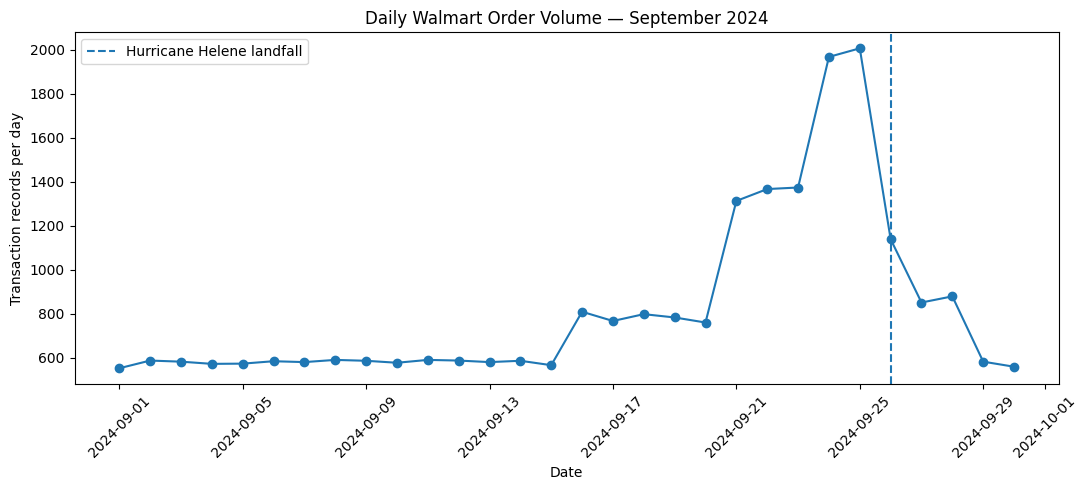

In [87]:

import matplotlib.pyplot as plt

# Use only records with valid timestamps
dated_sales = sales_clean.dropna(subset=["timestamp"]).copy()
dated_sales["date"] = dated_sales["timestamp"].dt.normalize()

# Count daily transaction records
daily_orders = (
    dated_sales.groupby("date")
    .size()
    .reset_index(name="orders")
    .sort_values("date")
)

# Define baseline and pre-landfall surge periods
baseline = daily_orders[
    daily_orders["date"].between("2024-09-08", "2024-09-15")
]

surge = daily_orders[
    daily_orders["date"].between("2024-09-23", "2024-09-25")
]

baseline_avg = baseline["orders"].mean()
surge_avg = surge["orders"].mean()
surge_multiple = surge_avg / baseline_avg

print(f"Baseline average: {baseline_avg:.1f} orders/day")
print(f"Surge average: {surge_avg:.1f} orders/day")
print(f"Surge multiple: {surge_multiple:.2f}x")

plt.figure(figsize=(11, 5))
plt.plot(daily_orders["date"], daily_orders["orders"], marker="o")
plt.axvline(pd.Timestamp("2024-09-26"),
            linestyle="--", label="Hurricane Helene landfall")
plt.title("Daily Walmart Order Volume — September 2024")
plt.xlabel("Date")
plt.ylabel("Transaction records per day")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [88]:

progress = {
    'rows_after_cleaning': len(sales_clean),
    'decisions_logged': len(decision_log),
    'canonical_products': canonical_products,
    'weather_api_rows': len(weather),
    'notebook_runs_clean': True,
}
check(required, progress)


REQUIRED
  FAIL - team_setup_complete = False
  PASS - charter_committed = True
PROGRESS (fill in what you have)
  done - rows_after_cleaning = 25532
  done - decisions_logged = 6
  done - canonical_products = 43
  done - weather_api_rows = 30
  done - notebook_runs_clean = True

required items complete: False
progress items done: 5 of 5


False

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

Biggest risk: The main problem would be that inconsistent identifiers for stores, and possibly inconsistent timestamps, might result in erroneous joins between Walmart’s sales data and the weather information. It may produce erroneous results as to hurricane-driven demand.

Plan, with an owner and a date: Suhail Abdulwasi, by October 28, 2026, I will examine the store IDs and timestamps, standardize their formats, and test a small sample join to identify mismatches before continuing the analysis.

### 8 — Where each question stands

**TODO:** mark each of the five questions. These owners must match the question owners table in your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | in progress| Suhail Abdulwasi |
| Q2 SKU consolidation | in progress | Suhail Abdulwasi |
| Q3 weather correlation | not started | Suhail Abdulwasi|
| Q4 store and geography | not started | Suhail Abdulwasi |
| Q5 signal or artifact | not started | Suhail Abdulwasi|

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.

Note Regarding Individual Project Work

I am currently completing this project independently and have reached out to my professor to discuss the possibility of working individually rather than in a team. I understand that the assignment specifies groups of 2–4 students, and I am awaiting confirmation regarding an exception. In the meantime, I have begun setting up my repository and documenting my progress to stay on track with the project requirements.